# Bayesian Classification
Henry Arnold, Cole Clodgo, Bao Lam, Nguyen Nguyen, Ryan Vo

In [ ]:
# module imports
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, ConfusionMatrixDisplay

## Getting the Data
We get the mnist dataset from keras already split into training and testing data. X_train and X_test contain the training and testing images as numpy arrays of pixels. Y_train and Y_test contain the digit labels for each image in X_train and X_test. We filter down to just two digits for our binary classification, choosing 7 and 9. To get the image data into a more workable form, we flatten them from 28x28 2D arrays down to a 1D array of 784 pixels, and convert the pixel values to floats for later calculations. The images remain grayscale rather than being converted to black and white.

In [ ]:
# get the data
(X_train, Y_train), (X_test, Y_test) = mnist.load_data()

# Choose two digits
digit1 = 7
digit2 = 9

# Keeping only the selected digits
train_mask = (Y_train == digit1) | (Y_train == digit2)
test_mask = (Y_test == digit1) | (Y_test == digit2)

X_train = X_train[train_mask]
Y_train = Y_train[train_mask]

X_test = X_test[test_mask]
Y_test = Y_test[test_mask]

# Flattening images from 28x28 to 784 pixels
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

# Convert to float for later calculations
X_train = X_train.astype(float)
X_test = X_test.astype(float)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: (12214, 784)
Testing samples: (2037, 784)


# Hand-Coded Normal Distribution

### 1. Train on Digit 7 and 9 (Mean, Variance, and Standard Deviation Calculation)

In [ ]:
# Mean
def mean(data_set):
    mean_array = np.mean(data_set, axis=0)
    return mean_array


# Standard deviation
def standard_deviation(data_set):
    std_array = np.std(data_set, axis=0)
    return std_array

# Smnooth variance to keep them from being zero in denominator
def smooth_variance(standard_deviation):
    variance = standard_deviation**2
    constant = (10**-9) * np.max(variance)
    return variance + constant


In [ ]:
# Execution

## Separate training images by digit
X_train_7 = X_train[Y_train == 7]
X_train_9 = X_train[Y_train == 9]

## Calculate mean arrays
mean_7 = mean(X_train_7)
mean_9 = mean(X_train_9)

## Calculate standard deviation arrays
sd_7 = standard_deviation(X_train_7)
sd_9 = standard_deviation(X_train_9)

## Calculate the smooth variance arrays
variance_7 = smooth_variance(sd_7)
variance_9 = smooth_variance(sd_9)

### 2. Prior Calculation

In [ ]:
# Prior function
def prior(label_set, chosen_class, other_class):
    chosen_count = np.sum(label_set == chosen_class)
    other_count = np.sum(label_set == other_class)
    return chosen_count / (chosen_count + other_count)

In [ ]:
# Execution

## Calculate prior for 7
prior_7 = prior(Y_train, 7, 9)

## Calculate prior for 9
prior_9 = prior(Y_train, 9, 7)

### 3. Gaussian Likelihood

In [ ]:
# Likelihood function
# Taking the log of the Gaussian likelihood function give us the formula for log likelihood
# Use that formula to derive the function

def log_likelihood(data_set, mean_array, variance_array):
    log_density = (-0.5 * np.log(2 * np.pi * variance_array) - ((data_set - mean_array)**2 / (2 * variance_array)))
    log_likelihood = np.sum(log_density, axis=1)

    return log_likelihood

In [ ]:
# Execution
log_likelihood_7 = log_likelihood(X_test, mean_7, variance_7)
log_likelihood_9 = log_likelihood(X_test, mean_9, variance_9)


### 4. Discriminant Function

In [ ]:
# Calculating gi(x)

g_7 = log_likelihood_7 + np.log(prior_7)
g_9 = log_likelihood_9 + np.log(prior_9)

### 5. Conmparison & Prediction

In [ ]:
# Predict 7 if g_7 larger than g_9
Y_pred = np.where(g_7 > g_9, 7, 9)

### 6. Model Evaluation

In [ ]:
# Accuracy
accuracy = accuracy_score(Y_test, Y_pred)

# F1 score (digit 9 as positive class)
f1 = f1_score(Y_test, Y_pred, pos_label=9)

# Confusion matrix
cm = confusion_matrix(Y_test, Y_pred, labels=[7, 9])

print("Accuracy:", accuracy)
print("F1 score:", f1)
print("Confusion matrix:\n", cm)

Accuracy: 0.6401570937653411
F1 score: 0.7294204503506829
Confusion matrix:
 [[316 712]
 [ 21 988]]


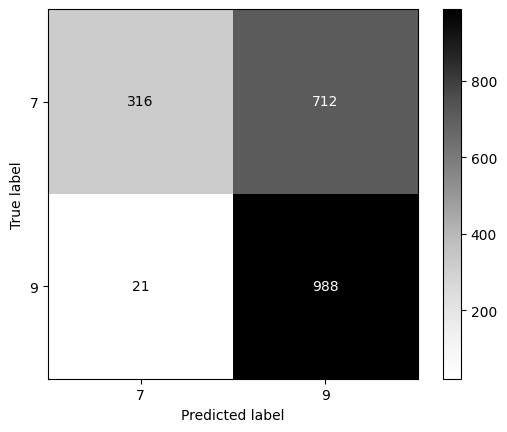

In [ ]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[7, 9]
).plot(cmap="Greys")

plt.show()

# Scikit-Learn Gaussian Distribution

### 1. Fit the Model

In [ ]:
# Initialize model
clf = GaussianNB()

# Fit the model using training data
clf.fit(X_train, Y_train)

# Predict test data
Y_pred_sklearn = clf.predict(X_test)

### 2. Evaluate the Model

In [ ]:
# Accuracy
accuracy_sklearn = accuracy_score(Y_test, Y_pred_sklearn)

# F1 score (digit 9 as positive class)
f1_sklearn = f1_score(Y_test, Y_pred_sklearn, pos_label=9)

# Confusion matrix
cm_sklearn = confusion_matrix(Y_test, Y_pred_sklearn, labels=[7, 9])

print("Accuracy:", accuracy_sklearn)
print("F1 Score:", f1_sklearn)
print("Confusion Matrix:\n", cm_sklearn)

Accuracy: 0.6406480117820325
F1 Score: 0.7296898079763663
Confusion Matrix:
 [[317 711]
 [ 21 988]]


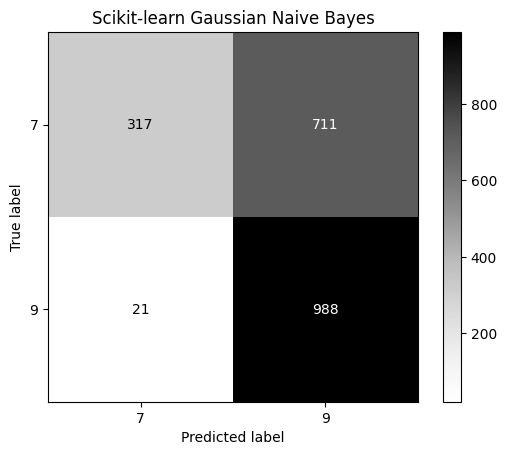

In [ ]:
ConfusionMatrixDisplay(
    confusion_matrix=cm_sklearn,
    display_labels=[7, 9]
).plot(cmap="Greys")

plt.title("Scikit-learn Gaussian Naive Bayes")
plt.show()